# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import ASDDataset
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3

## Show images and masks

Total number of patches: 80


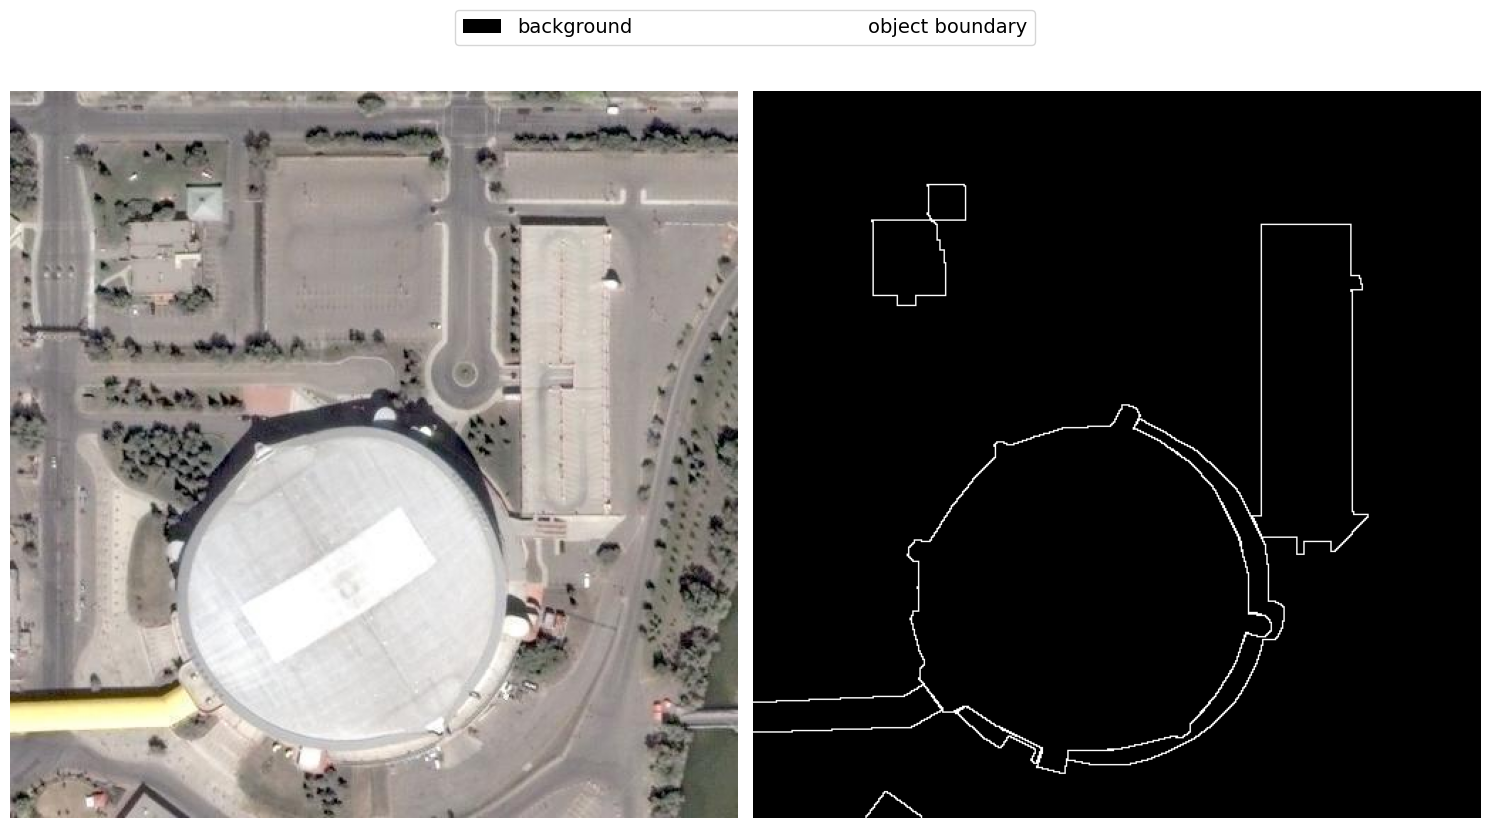

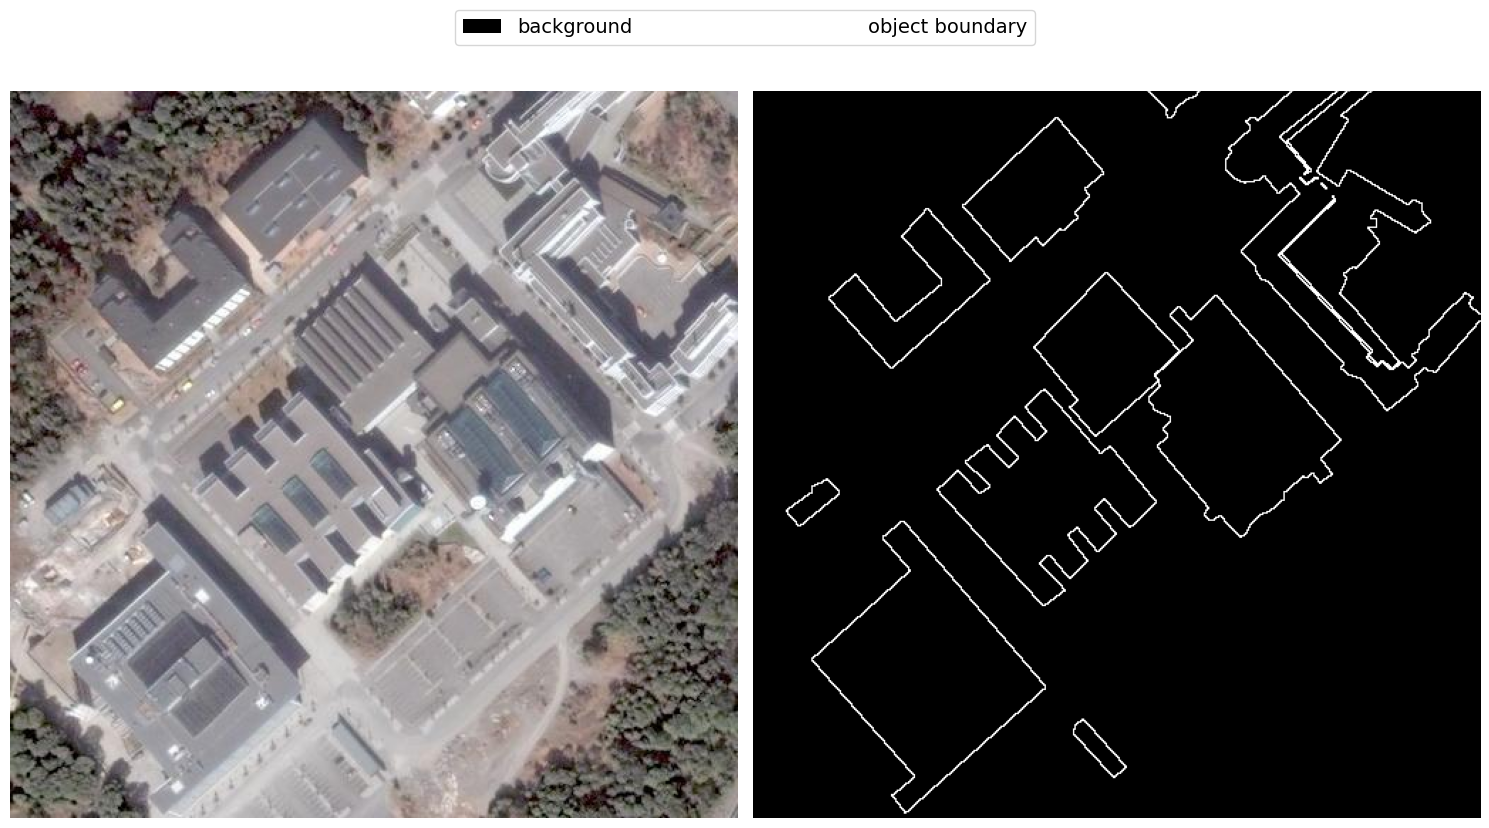

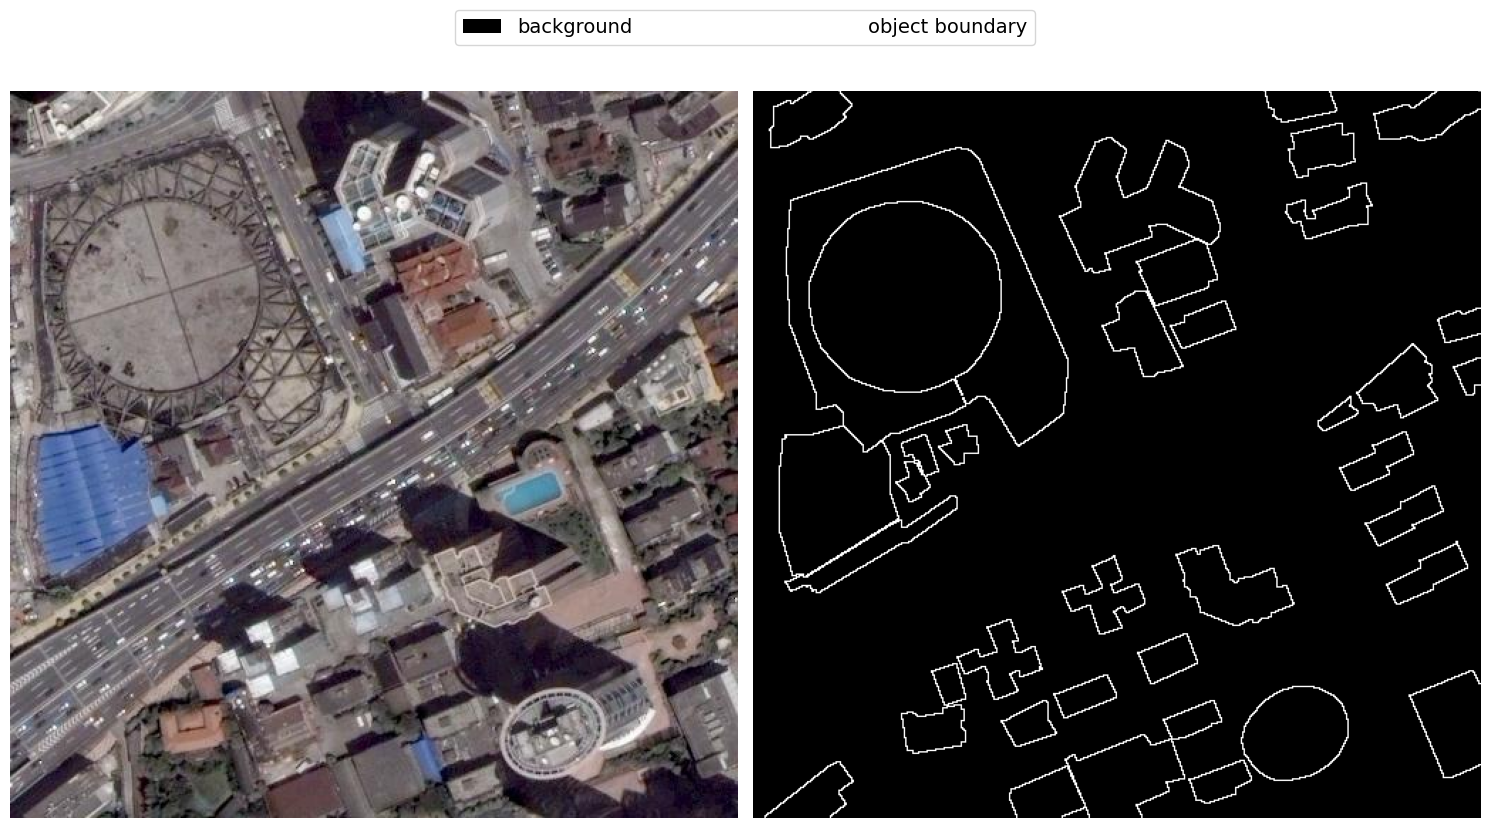

In [ ]:
dataset_config = {
    "data_dir": "./data/asd"
}
dataset = ASDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(20);
dataset.show_image(50);
dataset.show_image(65);

In [18]:
dataset.data_distribution_table()

,Number of pixels
background,20513873.0
object boundary,457647.0


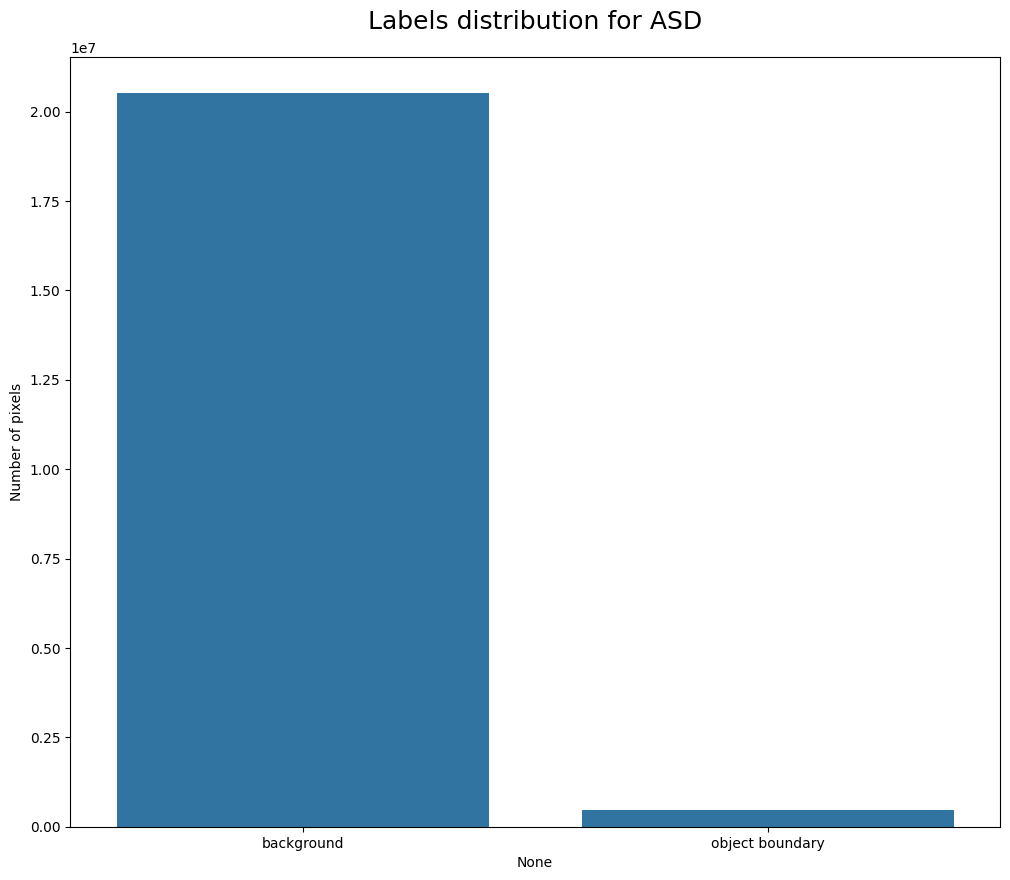

In [19]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/asd/",
    "csv_file": "./data/asd/asd_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = ASDDataset(train_dataset_config)
len(train_dataset)

48

## Create the model

In [ ]:
epochs = 100
model_directory = "./data/experiments/asd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [43]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-12-30 09:41:08,703 INFO Starting training.
training: 100%|██████████| 6/6 [00:01<00:00,  5.04it/s]
2025-12-30 09:41:09,988 INFO epoch: 1, time: 1, loss:  0.51178
testing on train set: 100%|██████████| 6/6 [00:00<00:00,  7.35it/s]
2025-12-30 09:41:13,087 INFO IOU:0.23301472083600583, IOU mean:0.23437150622854047, IOU per Class:[0.46874301 0.        ]
training: 100%|██████████| 6/6 [00:01<00:00,  5.37it/s]
2025-12-30 09:41:14,209 INFO epoch: 2, time: 1, loss:  0.49775
testing on train set: 100%|██████████| 6/6 [00:00<00:00,  7.42it/s]
2025-12-30 09:41:15,031 INFO IOU:0.2514883854556588, IOU mean:0.23875613359117534, IOU per Class:[0.47751227 0.        ]
training: 100%|██████████| 6/6 [00:01<00:00,  5.40it/s]
2025-12-30 09:41:16,147 INFO epoch: 3, time: 1, loss:  0.48175
testing on train set: 100%|██████████| 6/6 [00:00<00:00,  7.53it/s]
2025-12-30 09:41:16,958 INFO IOU:0.2535374541801115, IOU mean:0.2187565077288985, IOU per Class:[0.43751302 0.        ]
training: 100%|██████████| 6

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/asd/",
    "csv_file": "./data/asd/asd_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = ASDDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/asd/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

16


2025-12-30 09:44:35,870 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/asd/checkpoint.pth.tar
2025-12-30 09:44:36,343 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/asd/checkpoint.pth.tar at epoch 101
testing on test set: 100%|██████████| 4/4 [00:00<00:00,  6.72it/s]


[{'IOU': 0.8988265991210938,
  'IOU mean': 0.4494132995605469,
  'IOU per Class': array([0.8988266, 0.       ])}]

## Predictions

2025-12-30 10:36:51,400 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/asd/checkpoint.pth.tar
2025-12-30 10:36:51,798 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/asd/checkpoint.pth.tar at epoch 101


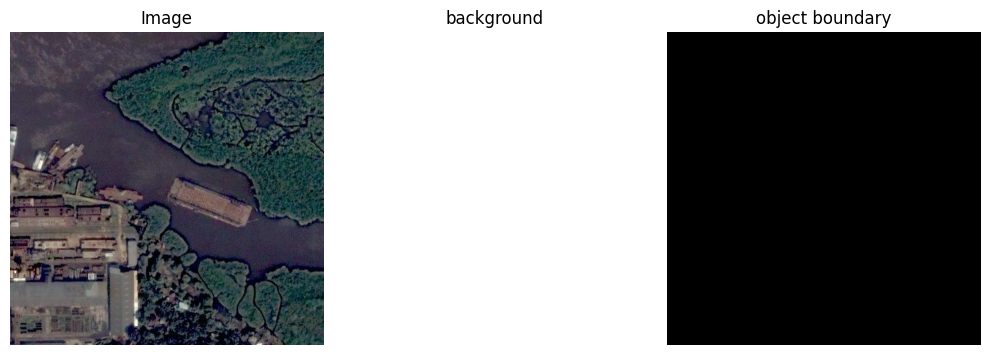

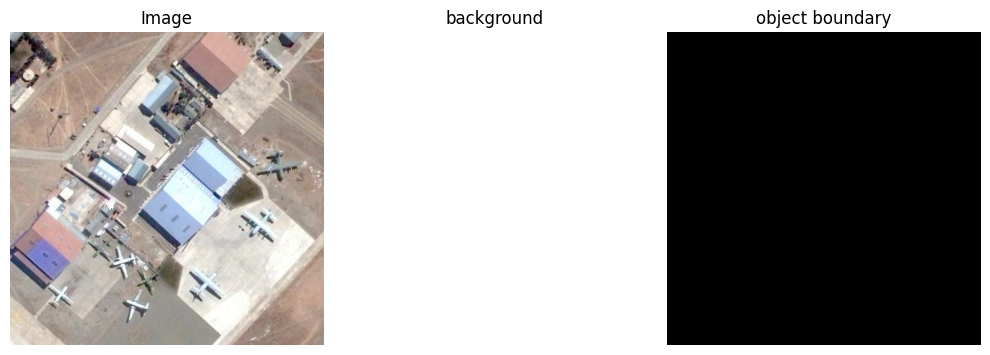

In [ ]:
model_path = "./data/experiments/asd/checkpoint.pth.tar"
labels = ["background","object boundary"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/asd/Images/00062.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/asd/Images/00034.jpg')
fig = model.predict_masks(image, labels, transform)